In [1]:
import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt

from gensim.models import Word2Vec
from gensim.utils import simple_preprocess

In [2]:
# --------------------------------------------------
# STEP 1: LOAD AND PREPROCESS TEXTUAL DOCUMENT
# --------------------------------------------------

# Read text document
with open("document3.txt", "r", encoding="utf-8") as file:
    text = file.read()

print("Original Document:")
print(text)

# Convert text into lowercase
text = text.lower()

# Split document into sentences
raw_sentences = re.split(r'[.!?]+', text)

# Tokenization and cleaning
sentences = [
    simple_preprocess(sentence, deacc=True)
    for sentence in raw_sentences
]

# Remove empty sentences
sentences = [
    sentence for sentence in sentences
    if len(sentence) > 0
]

print("\nTotal Sentences:", len(sentences))

print("\nTokenized Sentences:")
print(sentences)

Original Document:
The speed of transmission is an important point of difference between the two viruses. Influenza has a shorter median incubation period (the time from infection to appearance of symptoms) and a shorter serial interval (the time between successive cases) than COVID-19 virus. The serial interval for COVID-19 virus is estimated to be 5-6 days, while for influenza virus, the serial interval is 3 days. This means that influenza can spread faster than COVID-19. 

Further, transmission in the first 3-5 days of illness, or potentially pre-symptomatic transmission –transmission of the virus before the appearance of symptoms – is a major driver of transmission for influenza. In contrast, while we are learning that there are people who can shed COVID-19 virus 24-48 hours prior to symptom onset, at present, this does not appear to be a major driver of transmission. 

The reproductive number – the number of secondary infections generated from one infected individual – is understo

In [3]:
# --------------------------------------------------
# STEP 2: TRAIN CBOW WORD2VEC MODEL
# --------------------------------------------------

model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    sg=0,
    epochs=100
)

print("CBOW Word2Vec Model Trained Successfully")

# Display vocabulary size
print("Vocabulary Size:", len(model.wv))

CBOW Word2Vec Model Trained Successfully
Vocabulary Size: 92


In [4]:
# --------------------------------------------------
# STEP 3: EXTRACT WORD EMBEDDINGS
# --------------------------------------------------

# Select a word from vocabulary
word = 'influenza'

# Get word vector
word_vector = model.wv[word]

print("Word:", word)

print("\nWord Vector:")
print(word_vector)

print("\nVector Shape:", word_vector.shape)

Word: influenza

Word Vector:
[-6.23587379e-03  5.02411798e-02 -1.94260909e-03 -2.01048944e-02
  1.09366374e-02 -6.13935590e-02  4.94057275e-02  1.04536541e-01
 -4.85025197e-02 -4.68627624e-02 -2.74692979e-02 -7.62451068e-02
 -8.62981565e-03  4.95873997e-03  2.97577344e-02 -2.26287302e-02
  1.90051198e-02 -1.01336194e-02 -8.46296176e-03 -1.00225173e-01
  3.27306576e-02  2.33720466e-02  3.18819247e-02  3.95301310e-03
 -3.96976881e-02  9.08812881e-03 -3.01412772e-02 -1.80579387e-02
 -1.56454332e-02  1.94036551e-02  3.37617584e-02 -2.03526616e-02
  1.85895171e-02 -8.90567824e-02 -1.00998385e-02  5.51257916e-02
  5.02626263e-02 -7.85825122e-03  3.29426350e-03 -6.03028201e-02
  1.23726521e-02 -2.70695202e-02  1.10117497e-03 -9.43626463e-03
  4.04433347e-02 -2.29909131e-03 -4.49528694e-02 -6.45981869e-04
  5.48050404e-02  1.12234307e-02  1.56895840e-03 -3.72720510e-02
  2.40101907e-02 -9.88168549e-03 -1.27371335e-02 -4.56544367e-05
  2.97000948e-02 -8.18582345e-03 -2.65844911e-02 -9.94749274

In [5]:
# --------------------------------------------------
# STEP 4: FIND SIMILAR WORDS
# --------------------------------------------------

word = 'influenza'

similar_words = model.wv.most_similar(
    word,
    topn=5
)

print("Input Word:", word)

print("\nMost Similar Words:")

for w, score in similar_words:
    print(w, ":", score)

Input Word: influenza

Most Similar Words:
of : 0.9818516969680786
the : 0.9801504611968994
covid : 0.9800416231155396
transmission : 0.9791915416717529
are : 0.9783235788345337


In [6]:
# --------------------------------------------------
# STEP 5: CALCULATE WORD SIMILARITY
# --------------------------------------------------

word1 = 'influenza'
word2 = 'covid'

similarity = model.wv.similarity(
    word1,
    word2
)

print("Word 1:", word1)
print("Word 2:", word2)

print("Similarity Score:", similarity)

Word 1: influenza
Word 2: covid
Similarity Score: 0.9800416


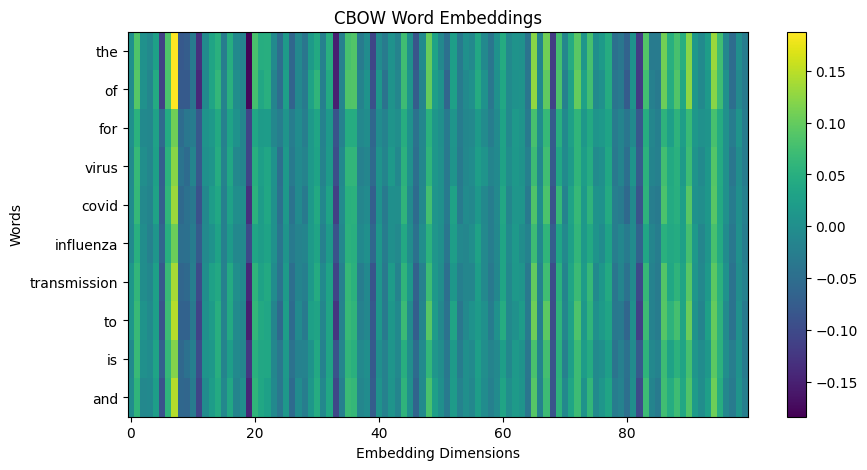

In [7]:
# --------------------------------------------------
# STEP 6: VISUALIZE WORD EMBEDDINGS
# --------------------------------------------------

# Select first 10 words
words = model.wv.index_to_key[:10]

# Get word vectors
vectors = np.array([
    model.wv[word]
    for word in words
])

# Plot embeddings
plt.figure(figsize=(10,5))

plt.imshow(vectors, aspect='auto', cmap='viridis')

plt.colorbar()

plt.yticks(range(len(words)), words)

plt.title("CBOW Word Embeddings")

plt.xlabel("Embedding Dimensions")

plt.ylabel("Words")

plt.show()

In [8]:
# --------------------------------------------------
# STEP 7: DISPLAY MODEL INFORMATION
# --------------------------------------------------

print("Total Vocabulary:", len(model.wv))

print("\nFirst 20 Words:")

print(model.wv.index_to_key[:20])

print("\nEmbedding Dimension:")

print(model.vector_size)

Total Vocabulary: 92

First 20 Words:
['the', 'of', 'for', 'virus', 'covid', 'influenza', 'transmission', 'to', 'is', 'and', 'are', 'days', 'be', 'than', 'interval', 'serial', 'time', 'between', 'number', 'driver']

Embedding Dimension:
100


In [9]:
# --------------------------------------------------
# STEP 8: SAVE CBOW MODEL
# --------------------------------------------------

model.save("document3_cbow.model")

print("CBOW Model Saved Successfully")

# Load saved model
loaded_model = Word2Vec.load("document3_cbow.model")

print("CBOW Model Loaded Successfully")

CBOW Model Saved Successfully
CBOW Model Loaded Successfully
